<a href="https://www.kaggle.com/code/minhtuan11/it2058-da?scriptVersionId=357877292" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [66]:
!pip install --upgrade torch torchvision torchaudio

#### SỬ dụng tỉ lệ của tập datashet 50 25 25

In [67]:
import os
import random
import numpy as np
import torch

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False  

SEED = 42
seed_everything(SEED)

In [68]:
import os
import pandas as pd

# Đường dẫn gốc chứa 3 thư mục: train, valid, test
base_dir = '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester'

def load_data_from_folder(split_name):
    folder_path = os.path.join(base_dir, split_name)
    filepaths, labels = [], []
    
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                filepaths.append(os.path.join(root, file))
                labels.append(os.path.basename(root))
                
    return pd.DataFrame({'filepath': filepaths, 'label': labels})

# 1. Đọc trực tiếp từ các thư mục có sẵn
train_df = load_data_from_folder('train')
val_df   = load_data_from_folder('valid')
test_df  = load_data_from_folder('test')

# 2. Ánh xạ nhãn sang dạng số
label_to_idx = {label: idx for idx, label in enumerate(train_df['label'].unique())}
train_df['label_idx'] = train_df['label'].map(label_to_idx)
val_df['label_idx']   = val_df['label'].map(label_to_idx)
test_df['label_idx']  = test_df['label'].map(label_to_idx)

# 3. Kiểm tra số lượng ảnh chính xác từ thư mục gốc
print(f"Tập Train: {len(train_df)} ảnh")
print(f"Tập Valid: {len(val_df)} ảnh")
print(f"Tập Test:  {len(test_df)} ảnh\n")

# Bảng tổng hợp chi tiết theo từng lớp
split_summary = pd.DataFrame({
    'Train': train_df['label'].value_counts(),
    'Valid': val_df['label'].value_counts(),
    'Test':  test_df['label'].value_counts()
}).fillna(0).astype(int)

print("--- Phân bố mẫu trong các thư mục gốc ---")
print(split_summary)

Tập Train: 3989 ảnh
Tập Valid: 1352 ảnh
Tập Test:  1379 ảnh

--- Phân bố mẫu trong các thư mục gốc ---
        Train  Valid  Test
label                     
Other    1490    628   689
V sign   1049    362   259
Flows     700    175   219
Aorta     490     96   133
X sign    260     91    79


#### Chia theo paper 60 20 20 

In [69]:
# import os
# import re
# import pandas as pd
# import numpy as np
# from sklearn.model_selection import GroupShuffleSplit

# base_dir = '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester'

# filepaths, labels, patient_ids = [], [], []

# for root, dirs, files in os.walk(base_dir):
#     for file in files:
#         if file.lower().endswith(('.png', '.jpg', '.jpeg')):
#             full_path = os.path.join(root, file)
            
#             # 1. Lấy tên lớp từ thư mục chứa file
#             label = os.path.basename(root)
            
#             # 2. Tách Mã Bệnh Nhân từ tên file (Ví dụ: "Flows test (137).png" -> "137")
#             match = re.search(r"\((\d+)\)", file)
#             patient_id = match.group(1) if match else os.path.splitext(file)[0]

#             filepaths.append(full_path)
#             labels.append(label)
#             patient_ids.append(patient_id)

# # Tạo DataFrame tổng
# df = pd.DataFrame({
#     'filepath': filepaths, 
#     'label': labels, 
#     'patient_id': patient_ids
# })

# # 3. TẠO CỘT 'label_idx' TRỰC TIẾP TRÊN DF GỐC (Tránh lỗi KeyError)
# unique_labels = sorted(df['label'].unique())
# label_to_idx = {label: idx for idx, label in enumerate(unique_labels)}
# df['label_idx'] = df['label'].map(label_to_idx)

# # 4. TẠO BỘ BIẾN XUẤT RA CHO BLOCK TRAIN
# num_classes = len(label_to_idx)
# target_names = [label for label, _ in sorted(label_to_idx.items(), key=lambda x: x[1])]

# # 5. CHIA TẬP THEO PATIENT-LEVEL (Train 60%, Valid 20%, Test 20%)
# gss_train = GroupShuffleSplit(n_splits=1, test_size=0.40, random_state=42)
# train_idx, temp_idx = next(gss_train.split(df, groups=df['patient_id']))

# train_df = df.iloc[train_idx].copy().reset_index(drop=True)
# temp_df  = df.iloc[temp_idx].copy().reset_index(drop=True)

# gss_val = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
# val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df['patient_id']))

# val_df  = temp_df.iloc[val_idx].copy().reset_index(drop=True)
# test_df = temp_df.iloc[test_idx].copy().reset_index(drop=True)

# print("=== HOÀN TẤT XỬ LÝ DỮ LIỆU (BLOCK 1) ===")
# print(f"Tổng số ảnh: {len(df)}")
# print(f"Danh sách các lớp ({num_classes} lớp): {target_names}")
# print(f"Số lượng bệnh nhân thực tế: {df['patient_id'].nunique()}")
# print(f"Phân bổ: Train={len(train_df)} | Valid={len(val_df)} | Test={len(test_df)} ảnh")
# print(f"Các cột đã sẵn sàng: {list(train_df.columns)}")

In [70]:
!find '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester/test' -type f | wc -l

1380


### Exit early

In [71]:
import torch
import torch.nn as nn

class ExitHead(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes):
        super().__init__()
        # 1. Conv 1x1: Giảm số lượng channel (giảm nhẹ tính toán)
        self.reduce_conv = nn.Conv2d(in_channels, hidden_channels, kernel_size=1)
        
        # 2. GAP (Global Average Pooling): Gom kích thước không gian (Ví dụ 28x28 -> 1x1)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        
        # 3. LayerNorm: Chuẩn hóa dữ liệu (PyTorch LayerNorm chuộng đầu vào 1D)
        self.norm = nn.LayerNorm(hidden_channels)
        
        # 4. Linear Classifier: Đưa ra xác suất dự đoán (Ví dụ 5 class tim thai nhi)
        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x):
        # x đầu vào có dạng [Batch, Channels, Height, Width]
        x = self.reduce_conv(x)
        x = self.gap(x)
        
        # Ép phẳng (Flatten) từ [Batch, Channels, 1, 1] thành vector [Batch, Channels]
        x = torch.flatten(x, start_dim=1)
        
        # Đưa qua Norm và Linear
        x = self.norm(x)
        out = self.classifier(x)
        return out

### Multi Exit Convnext

In [72]:
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

class MultiExitConvNeXt(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # 1. Tải mô hình ConvNeXt-Tiny pre-trained
        backbone = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        features = backbone.features
        
        # ==========================================
        # 2. RÃ MÔ HÌNH THÀNH 3 KHÚC (Slicing)
        # ==========================================
        # Khúc 1: Từ đầu đến hết Stage 2 (Bao gồm index 0, 1, 2, 3)
        self.part1 = features[:4]
        
        # Khúc 2: Downsample + Stage 3 (Index 4, 5)
        self.part2 = features[4:6]
        
        # Khúc 3: Downsample + Stage 4 (Index 6, 7)
        self.part3 = features[6:8]
        
        # ==========================================
        # 3. LẮP RÁP CÁC EXIT HEADS
        # ==========================================
        # Exit 1: Nằm sau Stage 2 (in_channels=192). Nén xuống 64 
        self.exit1 = ExitHead(in_channels=192, hidden_channels=64, num_classes=num_classes)
        
        # Exit 2: Nằm sau Stage 3 (in_channels=384). Nén xuống 128.
        self.exit2 = ExitHead(in_channels=384, hidden_channels=128, num_classes=num_classes)
        
        # Exit 3 (Main): Sửa lại Classifier gốc của ConvNeXt để ra 5 class
        self.avgpool = backbone.avgpool
        self.exit3 = backbone.classifier
        self.exit3[-1] = nn.Linear(768, num_classes) # Thay lớp Linear cuối cùng

    # ==========================================
    # 4. SỬA HÀM FORWARD CHẠY 3 KẾT QUẢ
    # ==========================================
    def forward(self, x):
        # Chạy Khúc 1 (Hết Stage 2)
        x = self.part1(x)
        y1 = self.exit1(x)       # <--- Rẽ nhánh lấy y1
        
        # Chạy tiếp Khúc 2 (Hết Stage 3)
        x = self.part2(x)
        y2 = self.exit2(x)       # <--- Rẽ nhánh lấy y2
        
        # Chạy nốt Khúc 3 (Full model - Hết Stage 4)
        x = self.part3(x)
        x = self.avgpool(x)      # Hàm pool gốc
        y3 = self.exit3(x)       # <--- Kết quả cuối y3
        
        return y1, y2, y3        # Trả về cả 3 logits

### Test 

In [73]:
if __name__ == "__main__":
    # Khởi tạo mô hình (ví dụ với 5 class: Aorta, Flows, Other, V sign, X sign)
    model = MultiExitConvNeXt(num_classes=5)
    
    # Tạo 1 batch ảo gồm 2 bức ảnh, kích thước 3 kênh màu, 224x224
    dummy_input = torch.randn(2, 3, 224, 224)
    
    # Đẩy ảnh qua mô hình
    y1, y2, y3 = model(dummy_input)
    
    print("Shape của Exit 1 (y1):", y1.shape) # Mong đợi: [2, 5]
    print("Shape của Exit 2 (y2):", y2.shape) # Mong đợi: [2, 5]
    print("Shape của Exit 3 (y3):", y3.shape) # Mong đợi: [2, 5]
    
    print("\n✅ Kiến trúc Multi-Exit đã hoạt động.")

Shape của Exit 1 (y1): torch.Size([2, 5])
Shape của Exit 2 (y2): torch.Size([2, 5])
Shape của Exit 3 (y3): torch.Size([2, 5])

✅ CHÚC MỪNG! BƯỚC 1 ĐÃ THÀNH CÔNG! Kiến trúc Multi-Exit đã hoạt động.


## Main

### Xử lí ảnh 

In [74]:
import cv2
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, f1_score
from torchinfo import summary

# Hàm tiền xử lý ảnh
def preprocess_ultrasound_image(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    return img

### PyTorch Dataset & DataLoaders

In [75]:
# ==========================================
# PYTORCH DATASET & DATALOADER
# ==========================================
class UltrasoundDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = self.df.loc[idx, 'label_idx']
        
        img_np = preprocess_ultrasound_image(img_path)
        img_pil = Image.fromarray(img_np)
        
        if self.transform:
            img_tensor = self.transform(img_pil)
        else:
            img_tensor = transforms.ToTensor()(img_pil)
            
        return img_tensor, torch.tensor(label, dtype=torch.long)

transform_pipeline = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Hàm khởi tạo seed cho từng worker
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)  # KHAI BÁO SEED

train_loader = DataLoader(
    UltrasoundDataset(train_df, transform_pipeline), 
    batch_size=32, 
    shuffle=True, 
    num_workers=2,
    worker_init_fn=seed_worker,  
    generator=g                
)
val_loader   = DataLoader(UltrasoundDataset(val_df, transform_pipeline), batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(UltrasoundDataset(test_df, transform_pipeline), batch_size=32, shuffle=False, num_workers=2)

### Focal Loss & Class Weights  

In [76]:
# ==========================================
# FOCAL LOSS & CLASS WEIGHTS
# ==========================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.alpha)
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label_idx']),
    y=train_df['label_idx'].values
)
alpha = torch.tensor(class_weights, dtype=torch.float)

### Khởi tạo mô hình & Tính toán khối lượng

In [77]:
# ==========================================
# KHỞI TẠO MÔ HÌNH MULTI-EXIT
# ==========================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang chạy trên thiết bị: {device}\n")

# Khởi tạo mô hình MultiExitConvNeXt
num_classes = 5
model = MultiExitConvNeXt(num_classes=num_classes)
model = model.to(device)

# In bảng cấu trúc và số lượng tham số / FLOPs
print("\n--- BẢNG CẤU TRÚC VÀ KHỐI LƯỢNG TÍNH TOÁN CỦA MÔ HÌNH ---")
summary(model, input_size=(32, 3, 224, 224))
print("-" * 60 + "\n")

Đang chạy trên thiết bị: cuda


--- BẢNG CẤU TRÚC VÀ KHỐI LƯỢNG TÍNH TOÁN CỦA MÔ HÌNH ---
------------------------------------------------------------



### Training

In [78]:
# ==========================================
# CẤU HÌNH LOSS, OPTIMIZER & MẠNG TRAIN
# ==========================================
criterion = FocalLoss(alpha=alpha.to(device), gamma=2)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.05)

epochs = 15
patience = 4
best_val_f1 = 0.0
best_epoch = 0
early_stop_counter = 0
best_model_wts = copy.deepcopy(model.state_dict())

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}

print(f"{'Epoch':<8} | {'Train Loss':<10} | {'Train Acc':<10} | {'Val Loss':<10} | {'Val Acc':<10} | {'Val Macro F1':<12} | Status")
print("-" * 80)

for epoch in range(epochs):
    # --- TRAINING ---
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        
        outputs = model(images)
        
        # --- LƯU Ý KHI DÙNG MULTI-EXIT ---
        # Trường hợp 1: Nếu outputs trả về 1 Tensor duy nhất (Exit cuối)
        if isinstance(outputs, torch.Tensor):
            loss = criterion(outputs, labels)
            preds = outputs
        # Trường hợp 2: Nếu outputs trả về tuple/list các exits (ví dụ: [exit1, exit2, exit_final])
        else:
            loss = sum(criterion(out, labels) for out in outputs) # Cộng tổng loss các exit
            preds = outputs[-1] # Lấy exit cuối cùng để tính accuracy
            
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = preds.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()
            
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = train_correct / train_total
    
    # --- VALIDATION ---
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            
            if isinstance(outputs, torch.Tensor):
                loss = criterion(outputs, labels)
                preds = outputs
            else:
                loss = criterion(outputs[-1], labels) # Khi val chỉ tính loss exit cuối
                preds = outputs[-1]
            
            val_loss += loss.item() * images.size(0)
            _, predicted = preds.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total
    val_f1_macro = f1_score(all_labels, all_preds, average='macro')
    
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_acc'].append(epoch_val_acc)
    history['val_f1'].append(val_f1_macro)
    
    # --- CHECKPOINT & EARLY STOPPING ---
    status = ""
    if val_f1_macro > best_val_f1:
        best_val_f1 = val_f1_macro
        best_epoch = epoch + 1
        best_model_wts = copy.deepcopy(model.state_dict())
        early_stop_counter = 0
        status = "[Saved Best]"
    else:
        early_stop_counter += 1
        status = f"Patience {early_stop_counter}/{patience}"
        
    print(f"{epoch+1:02d}/{epochs:02d}    | {epoch_train_loss:<10.4f} | {epoch_train_acc*100:<9.2f}% | {epoch_val_loss:<10.4f} | {epoch_val_acc*100:<9.2f}% | {val_f1_macro:<12.4f} | {status}")
    
    if early_stop_counter >= patience:
        print(f"\n=> EARLY STOPPING kích hoạt ở Epoch {epoch+1}.")
        break

# Tải lại trọng số tốt nhất
model.load_state_dict(best_model_wts)

Epoch    | Train Loss | Train Acc  | Val Loss   | Val Acc    | Val Macro F1 | Status
--------------------------------------------------------------------------------
01/15    | 2.3348     | 78.47    % | 0.3233     | 75.44    % | 0.7047       | [Saved Best]
02/15    | 1.1727     | 94.81    % | 0.2300     | 80.47    % | 0.7584       | [Saved Best]
03/15    | 1.0361     | 96.97    % | 0.2822     | 88.39    % | 0.8327       | [Saved Best]
04/15    | 0.7709     | 98.60    % | 0.1839     | 84.91    % | 0.7986       | Patience 1/4
05/15    | 0.4132     | 97.94    % | 0.2636     | 84.25    % | 0.7862       | Patience 2/4
06/15    | 0.2267     | 99.72    % | 0.1969     | 88.54    % | 0.8454       | [Saved Best]
07/15    | 0.1089     | 99.90    % | 0.3495     | 86.76    % | 0.8036       | Patience 1/4
08/15    | 0.0939     | 99.57    % | 0.2378     | 87.94    % | 0.8395       | Patience 2/4
10/15    | 0.1132     | 98.62    % | 0.3001     | 90.68    % | 0.8540       | [Saved Best]
11/15    | 0.04

<All keys matched successfully>

### Đồ thị 

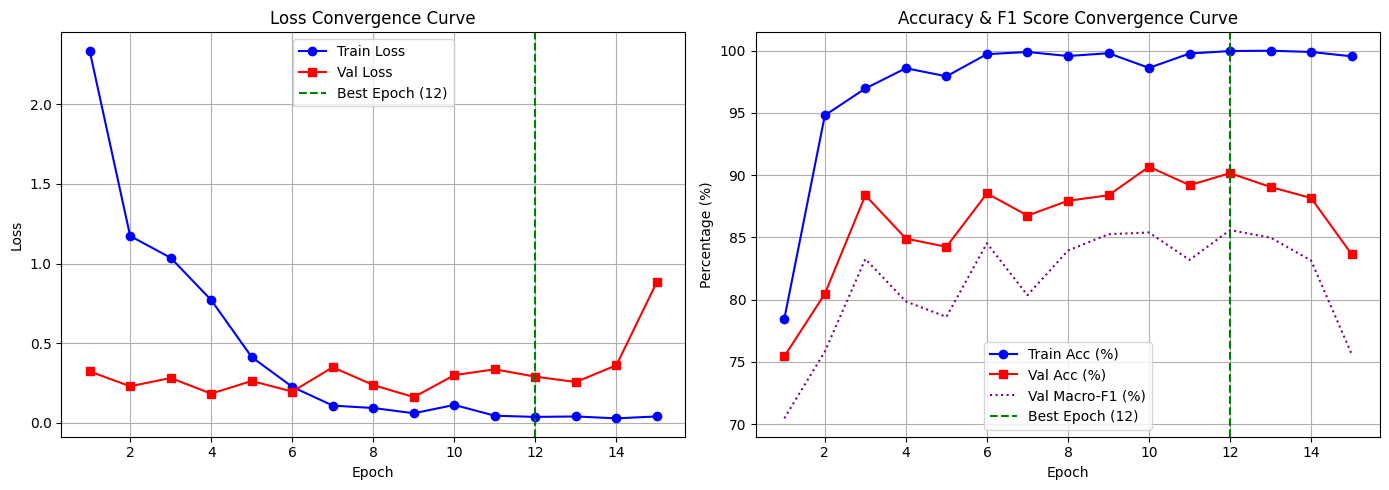

In [79]:
# ==========================================
# VẼ ĐỒ THỊ SỰ HỘI TỤ
# ==========================================
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(history['train_loss'])+1), history['train_loss'], label='Train Loss', color='blue', marker='o')
plt.plot(range(1, len(history['val_loss'])+1), history['val_loss'], label='Val Loss', color='red', marker='s')
plt.axvline(x=best_epoch, color='green', linestyle='--', label=f'Best Epoch ({best_epoch})')
plt.title('Loss Convergence Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(history['train_acc'])+1), [x*100 for x in history['train_acc']], label='Train Acc (%)', color='blue', marker='o')
plt.plot(range(1, len(history['val_acc'])+1), [x*100 for x in history['val_acc']], label='Val Acc (%)', color='red', marker='s')
plt.plot(range(1, len(history['val_f1'])+1), [x*100 for x in history['val_f1']], label='Val Macro-F1 (%)', color='purple', linestyle=':')
plt.axvline(x=best_epoch, color='green', linestyle='--', label=f'Best Epoch ({best_epoch})')
plt.title('Accuracy & F1 Score Convergence Curve')
plt.xlabel('Epoch')
plt.ylabel('Percentage (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Đánh giá 

In [80]:
# ==========================================
# ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST
# ==========================================
print("\n" + "="*50)
print(f" THÔNG TIN MÔ HÌNH TỐT NHẤT (Đạt được ở Epoch {best_epoch})")
print("="*50)

model.eval()
test_preds, test_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        
        preds = outputs if isinstance(outputs, torch.Tensor) else outputs[-1]
        
        _, predicted = preds.max(1)
        test_preds.extend(predicted.cpu().numpy())
        test_labels.extend(labels.numpy())

print("\n[Báo Cáo Chi Tiết Trên Tập Test (Unseen Data)]")
print(classification_report(test_labels, test_preds, target_names=target_names, digits=4))


 THÔNG TIN MÔ HÌNH TỐT NHẤT (Đạt được ở Epoch 12)

[Báo Cáo Chi Tiết Trên Tập Test (Unseen Data)]
              precision    recall  f1-score   support

       Aorta     0.9776    0.9954    0.9864       219
       Flows     0.9826    0.8999    0.9394       689
       Other     0.7593    0.9248    0.8339       133
      V sign     0.9051    0.9575    0.9306       259
      X sign     0.7640    0.8608    0.8095        79

    accuracy                         0.9260      1379
   macro avg     0.8777    0.9277    0.9000      1379
weighted avg     0.9332    0.9260    0.9276      1379



In [81]:
# ==========================================================
# SCRIPT ĐÁNH GIÁ HIỆU NĂNG CỦA TỪNG EXIT HEAD TRÊN TẬP TEST
# ==========================================================
import numpy as np
import torch
from sklearn.metrics import classification_report, accuracy_score, f1_score

print("\n" + "="*60, flush=True)
print("  ĐÁNH GIÁ HIỆU NĂNG CỦA TỪNG EXIT HEAD TRÊN TẬP TEST", flush=True)
print("="*60, flush=True)

model.eval()

# 1. Kiểm tra số lượng Exit Head của mô hình
with torch.no_grad():
    sample_img, _ = next(iter(test_loader))
    sample_out = model(sample_img.to(device))
    
    if isinstance(sample_out, (list, tuple)):
        num_exits = len(sample_out)
        print(f"-> Phát hiện mô hình Multi-Exit có tổng cộng {num_exits} Exit Heads.\n", flush=True)
    else:
        num_exits = 1
        print("-> Mô hình chỉ trả về 1 đầu ra duy nhất.\n", flush=True)

if num_exits > 1:
    # Mảng lưu dự đoán riêng cho từng Exit
    all_exit_preds = [[] for _ in range(num_exits)]
    all_test_labels = []

    # 2. Chạy dự đoán trên toàn bộ tập Test
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images) # Trả về list/tuple các Exit
            
            all_test_labels.extend(labels.numpy())
            
            # Thu thập dự đoán của từng Exit Head
            for idx, exit_out in enumerate(outputs):
                _, predicted = exit_out.max(1)
                all_exit_preds[idx].extend(predicted.cpu().numpy())

    # 3. In Bảng So Sánh Tổng Quan
    print(f"{'Exit Head':<12} | {'Accuracy (%)':<15} | {'Macro F1-Score':<15}")
    print("-" * 50, flush=True)

    for idx in range(num_exits):
        acc = accuracy_score(all_test_labels, all_exit_preds[idx]) * 100
        f1 = f1_score(all_test_labels, all_exit_preds[idx], average='macro')
        print(f"Exit {idx+1:<7} | {acc:<15.2f} | {f1:<15.4f}", flush=True)

    print("=" * 50 + "\n", flush=True)

    # 4. In Báo Cáo Chi Tiết Cho Từng Exit Head
    for idx in range(num_exits):
        print(f"\n[BÁO CÁO CHI TIẾT - EXIT HEAD {idx+1}]", flush=True)
        print(classification_report(all_test_labels, all_exit_preds[idx], target_names=target_names, digits=4), flush=True)

else:
    print("Mô hình không phải dạng Multi-Exit, không cần tách đánh giá.")


  ĐÁNH GIÁ HIỆU NĂNG CỦA TỪNG EXIT HEAD TRÊN TẬP TEST
-> Phát hiện mô hình Multi-Exit có tổng cộng 3 Exit Heads.

Exit Head    | Accuracy (%)    | Macro F1-Score 
--------------------------------------------------
Exit 1       | 84.19           | 0.7767         
Exit 2       | 92.89           | 0.8994         
Exit 3       | 92.60           | 0.9000         


[BÁO CÁO CHI TIẾT - EXIT HEAD 1]
              precision    recall  f1-score   support

       Aorta     0.8760    1.0000    0.9339       219
       Flows     0.9780    0.8389    0.9031       689
       Other     0.6424    0.7293    0.6831       133
      V sign     0.7570    0.8301    0.7919       259
      X sign     0.5049    0.6582    0.5714        79

    accuracy                         0.8419      1379
   macro avg     0.7517    0.8113    0.7767      1379
weighted avg     0.8608    0.8419    0.8469      1379


[BÁO CÁO CHI TIẾT - EXIT HEAD 2]
              precision    recall  f1-score   support

       Aorta     0.9820  